## Step 1: Data Preparation and Class Balance

In this project, I am using the Bank Marketing dataset to predict
whether a customer will subscribe to a term deposit.

The dataset contains more customers who did not subscribe than
customers who subscribed. Therefore, this is an imbalanced
classification problem.

The goal is to improve the model's ability to identify the
minority class (yes).

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.utils import resample

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
import pandas as pd
import requests
import zipfile
from io import BytesIO

# Official UCI Bank Marketing dataset
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

# Download dataset
response = requests.get(url, timeout=60)
response.raise_for_status()

# Open the outer ZIP file
with zipfile.ZipFile(BytesIO(response.content)) as outer_zip:

    # Find the nested bank.zip file
    nested_zip_name = next(
        name for name in outer_zip.namelist()
        if name.endswith("bank.zip")
    )

    # Read the nested ZIP file
    nested_zip_data = outer_zip.read(nested_zip_name)

    # Open the nested ZIP
    with zipfile.ZipFile(BytesIO(nested_zip_data)) as inner_zip:

        # Find bank-full.csv
        csv_file = next(
            name for name in inner_zip.namelist()
            if name.endswith("bank-full.csv")
        )

        # Load dataset
        with inner_zip.open(csv_file) as file:
            df = pd.read_csv(file, sep=';')

print("Dataset loaded successfully!")

# Display first five rows
display(df.head())

# Dataset information
print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset loaded successfully!


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Dataset Shape: (45211, 17)

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  i

In [8]:
# Display first five rows
display(df.head())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Dataset Shape: (45211, 17)

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  in

In [9]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Replace unknown values with NaN in categorical columns
categorical_columns = df.select_dtypes(
    include=['object']
).columns.tolist()

for col in categorical_columns:
    df[col] = df[col].replace('unknown', np.nan)

# Check missing values after cleaning
print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nUpdated Dataset Shape:", df.shape)

Missing Values After Cleaning:
age              0
job            288
marital          0
education     1857
default          0
balance          0
housing          0
loan             0
contact      13020
day              0
month            0
duration         0
campaign         0
pdays            0
previous         0
poutcome     36959
y                0
dtype: int64

Updated Dataset Shape: (45211, 17)


In [10]:
# Separate features and target
X = df.drop('y', axis=1)
y = df['y'].map({'no': 0, 'yes': 1})

# Check target values
print("Target Values:")
print(y.value_counts())

print("\nTarget Classes:")
print(y.value_counts().index.tolist())

Target Values:
y
0    39922
1     5289
Name: count, dtype: int64

Target Classes:
[0, 1]


Class Distribution:
y
0    39922
1     5289
Name: count, dtype: int64

Class Percentages:
y
0    88.3
1    11.7
Name: proportion, dtype: float64


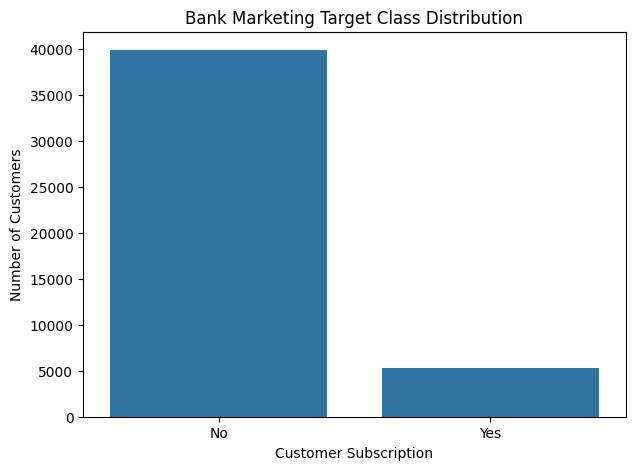

In [11]:
# Count target classes
class_counts = y.value_counts()

print("Class Distribution:")
print(class_counts)

# Calculate percentages
print("\nClass Percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

# Plot class distribution
plt.figure(figsize=(7, 5))

sns.countplot(x=y.map({0: 'No', 1: 'Yes'}))

plt.title("Bank Marketing Target Class Distribution")
plt.xlabel("Customer Subscription")
plt.ylabel("Number of Customers")

plt.show()

In [14]:
# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

Training data shape: (36168, 16)
Testing data shape: (9043, 16)

Training target distribution:
y
0    31937
1     4231
Name: count, dtype: int64


In [13]:
# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

print("\nPreprocessing pipeline created successfully!")

Numerical Features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Preprocessing pipeline created successfully!


The dataset is imbalanced because approximately 88.3% of customers did not subscribe, while only 11.7% subscribed. A model may become biased toward predicting the majority class and fail to identify potential subscribers.

## Step 2: Baseline Models

In this step, I will train two baseline models: DummyClassifier
and RandomForestClassifier.

The DummyClassifier predicts the majority class for every customer,
while RandomForestClassifier learns patterns from the training data.

I will evaluate both models using a validation set created from
the training data. The test set will remain untouched until Step 7.

In [15]:
# Split training data into training and validation sets

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training Subset:", X_train_sub.shape)
print("Validation Set:", X_val.shape)

print("\nTraining Subset Class Distribution:")
print(y_train_sub.value_counts())

print("\nValidation Class Distribution:")
print(y_val.value_counts())

Training Subset: (28934, 16)
Validation Set: (7234, 16)

Training Subset Class Distribution:
y
0    25549
1     3385
Name: count, dtype: int64

Validation Class Distribution:
y
0    6388
1     846
Name: count, dtype: int64


In [16]:
# Create Dummy Classifier
dummy_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

# Train model
dummy_model.fit(X_train_sub, y_train_sub)

# Make predictions
dummy_pred = dummy_model.predict(X_val)

# Evaluate model
print("DUMMY CLASSIFIER RESULTS")

print("\nAccuracy:", accuracy_score(y_val, dummy_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    dummy_pred,
    target_names=['No', 'Yes'],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, dummy_pred, labels=[0, 1]))

# Calculate missed rare-class cases
dummy_cm = confusion_matrix(y_val, dummy_pred, labels=[0, 1])
dummy_fn = dummy_cm[1, 0]

print("\nRare-class cases missed (False Negatives):", dummy_fn)

DUMMY CLASSIFIER RESULTS

Accuracy: 0.8830522532485485

Classification Report:
              precision    recall  f1-score   support

          No       0.88      1.00      0.94      6388
         Yes       0.00      0.00      0.00       846

    accuracy                           0.88      7234
   macro avg       0.44      0.50      0.47      7234
weighted avg       0.78      0.88      0.83      7234


Confusion Matrix:
[[6388    0]
 [ 846    0]]

Rare-class cases missed (False Negatives): 846


### Dummy Classifier Analysis

The DummyClassifier achieved 88.31% accuracy, which initially
looks good. However, it predicted every customer as a non-subscriber.

As a result, it failed to identify all 846 actual subscribers
in the validation set. Its recall, precision and F1-score for
the minority class were all zero.

This shows that accuracy is misleading for imbalanced datasets.
A model must also be evaluated using recall, precision and F1-score.

In [17]:
# Create default Random Forest Classifier
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Train model
rf_model.fit(X_train_sub, y_train_sub)

# Make predictions
rf_pred = rf_model.predict(X_val)

# Evaluate model
print("RANDOM FOREST RESULTS")

print("\nAccuracy:", accuracy_score(y_val, rf_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_pred,
    target_names=['No', 'Yes'],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_pred, labels=[0, 1]))

# Calculate missed rare-class cases
rf_cm = confusion_matrix(y_val, rf_pred, labels=[0, 1])
rf_fn = rf_cm[1, 0]

print("\nRare-class cases missed (False Negatives):", rf_fn)

RANDOM FOREST RESULTS

Accuracy: 0.9029582526956041

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.98      0.95      6388
         Yes       0.66      0.35      0.46       846

    accuracy                           0.90      7234
   macro avg       0.79      0.67      0.70      7234
weighted avg       0.89      0.90      0.89      7234


Confusion Matrix:
[[6232  156]
 [ 546  300]]

Rare-class cases missed (False Negatives): 546


### Random Forest Baseline Analysis

The Random Forest achieved 90.30% accuracy, which is higher
than the DummyClassifier.

However, its recall for the minority class (yes) was only
0.35, meaning it identified approximately 35% of actual
subscribers.

Out of 846 actual subscribers, the model correctly identified
300 and missed 546.

Although Random Forest performed better than the DummyClassifier,
it still struggles to identify the minority class. Therefore,
we need to improve its recall.

In [18]:
# Compare baseline models

baseline_results = pd.DataFrame({
    'Model': ['Dummy Classifier', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_val, dummy_pred),
        accuracy_score(y_val, rf_pred)
    ],
    'Precision': [
        precision_score(y_val, dummy_pred, zero_division=0),
        precision_score(y_val, rf_pred, zero_division=0)
    ],
    'Recall': [
        recall_score(y_val, dummy_pred, zero_division=0),
        recall_score(y_val, rf_pred, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_val, dummy_pred, zero_division=0),
        f1_score(y_val, rf_pred, zero_division=0)
    ],
    'False Negatives': [dummy_fn, rf_fn]
})

display(baseline_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,False Negatives
0,Dummy Classifier,0.8831,0.0000,0.0000,0.0000,846
1,Random Forest,0.9030,0.6579,0.3546,0.4608,546


## Step 3: Choosing the Evaluation Metric

For this Bank Marketing problem, I have selected Recall as my
main evaluation metric.

A False Negative occurs when the model predicts that a customer
will not subscribe, but the customer actually subscribes.

This mistake is more important because we may lose potential
customers who are interested in the bank's term deposit.

Recall helps us identify as many actual subscribers as possible.
However, I will also monitor Precision because higher recall may
increase false positives and unnecessary marketing efforts.

In [19]:
# Understanding classification metrics

print("Main Metric: Recall")
print("Other Important Metrics: Precision and F1 Score")

print("\nRecall = TP / (TP + FN)")
print("Precision = TP / (TP + FP)")
print("F1 Score = 2 * (Precision * Recall) / (Precision + Recall)")

Main Metric: Recall
Other Important Metrics: Precision and F1 Score

Recall = TP / (TP + FN)
Precision = TP / (TP + FP)
F1 Score = 2 * (Precision * Recall) / (Precision + Recall)


## Step 4: Error Analysis

In this step, I will investigate the mistakes made by the
baseline Random Forest model.

I will identify False Negatives and False Positives and
compare their feature values with correctly classified customers.

The purpose is to understand which customer characteristics
may contribute to incorrect predictions and why the model
struggles to identify potential subscribers.

In [21]:
# Create a DataFrame containing validation data and predictions

error_analysis = X_val.copy()

error_analysis['Actual'] = y_val
error_analysis['Predicted'] = rf_pred

# Identify prediction categories
error_analysis['Result'] = np.select(
    [
        (error_analysis['Actual'] == 1) &
        (error_analysis['Predicted'] == 0),

        (error_analysis['Actual'] == 0) &
        (error_analysis['Predicted'] == 1),

        (error_analysis['Actual'] == 1) &
        (error_analysis['Predicted'] == 1),

        (error_analysis['Actual'] == 0) &
        (error_analysis['Predicted'] == 0)
    ],
    [
        'False Negative',
        'False Positive',
        'True Positive',
        'True Negative'
    ],
    default='Unknown'
)

# Separate the four groups
false_negatives = error_analysis[
    error_analysis['Result'] == 'False Negative'
]

false_positives = error_analysis[
    error_analysis['Result'] == 'False Positive'
]

true_positives = error_analysis[
    error_analysis['Result'] == 'True Positive'
]

true_negatives = error_analysis[
    error_analysis['Result'] == 'True Negative'
]

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))
print("True Positives:", len(true_positives))
print("True Negatives:", len(true_negatives))

False Negatives: 546
False Positives: 156
True Positives: 300
True Negatives: 6232


In [22]:
# Select numerical columns
numeric_cols = X_val.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Compare numerical feature statistics
print("FALSE NEGATIVES - Numerical Features")
display(false_negatives[numeric_cols].describe().round(2))

print("\nTRUE POSITIVES - Numerical Features")
display(true_positives[numeric_cols].describe().round(2))

FALSE NEGATIVES - Numerical Features


,age,balance,day,duration,campaign,pdays,previous
count,546.00,546.00,546.00,546.00,546.00,546.00,546.00
mean,41.49,1832.19,15.05,481.88,2.31,50.18,0.77
std,13.54,3092.94,8.70,323.64,1.98,112.61,1.96
min,18.00,-970.00,1.00,34.00,1.00,-1.00,0.00
25%,31.00,200.25,7.25,224.25,1.00,-1.00,0.00
50%,38.00,723.00,14.00,401.00,2.00,-1.00,0.00
75%,51.00,2231.50,22.00,674.50,3.00,-1.00,0.00
max,90.00,29340.00,31.00,2184.00,21.00,784.00,17.00



TRUE POSITIVES - Numerical Features


,age,balance,day,duration,campaign,pdays,previous
count,300.00,300.00,300.00,300.00,300.00,300.00,300.00
mean,41.57,1708.53,16.17,643.73,2.10,94.04,1.89
std,14.06,2495.66,8.66,464.47,1.66,119.61,2.88
min,20.00,-271.00,1.00,133.00,1.00,-1.00,0.00
25%,31.00,239.50,10.00,278.00,1.00,-1.00,0.00
50%,38.00,829.50,15.00,457.00,1.50,87.00,1.00
75%,50.00,2076.50,23.00,964.75,3.00,179.25,3.00
max,90.00,23878.00,31.00,2692.00,10.00,804.00,21.00


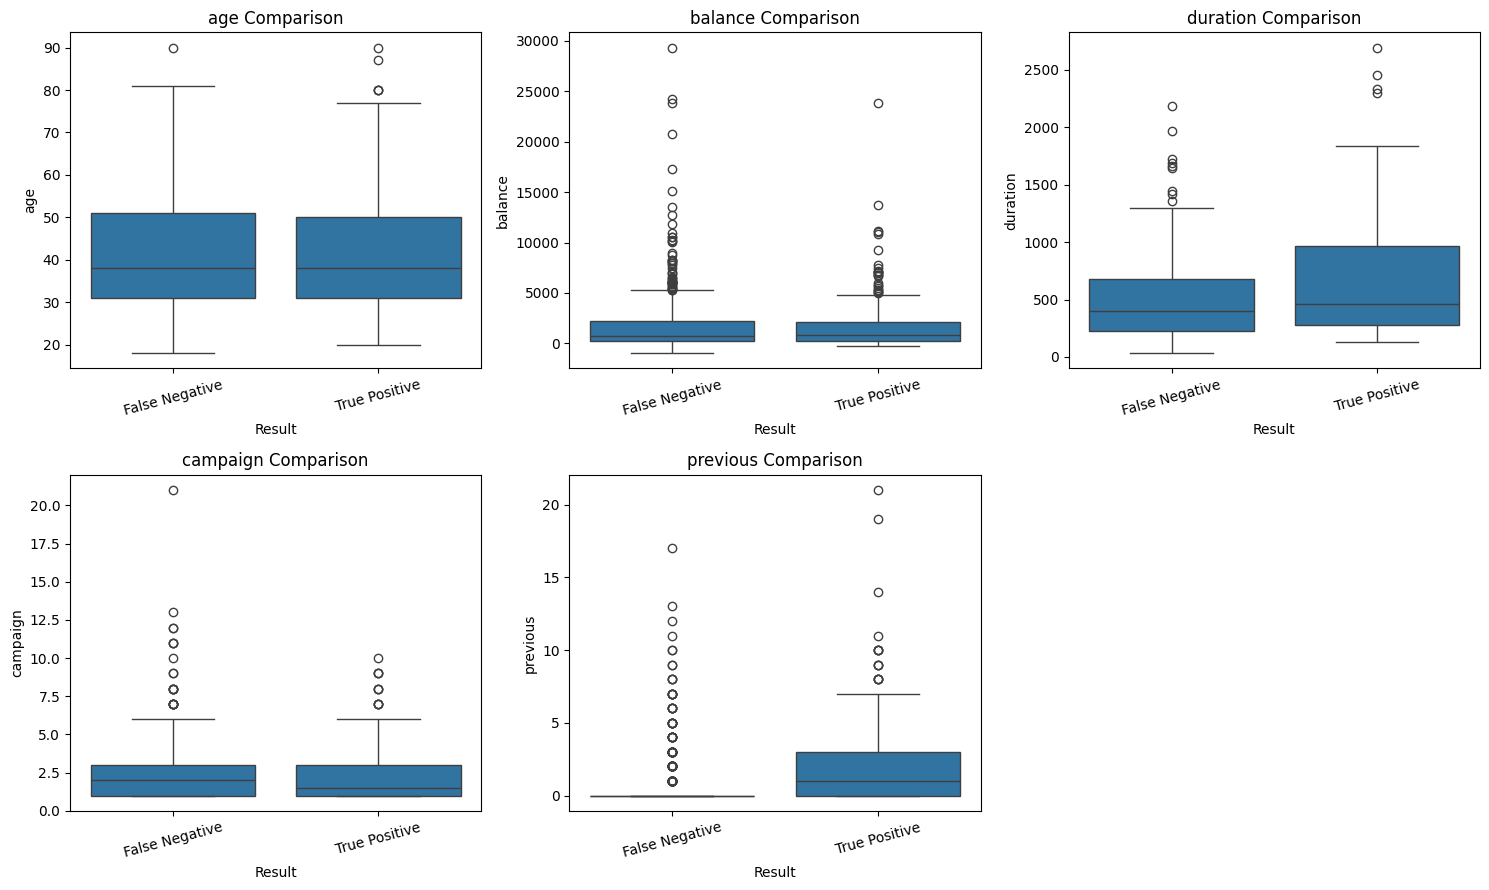

In [23]:
# Compare important numerical features
features_to_plot = ['age', 'balance', 'duration',
                    'campaign', 'previous']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):

    sns.boxplot(
        data=error_analysis[
            error_analysis['Result'].isin(
                ['False Negative', 'True Positive']
            )
        ],
        x='Result',
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f'{feature} Comparison')
    axes[i].tick_params(axis='x', rotation=15)

# Remove unused subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

In [24]:
# Select categorical columns
categorical_cols = X_val.select_dtypes(
    include=['object']
).columns.tolist()

# Compare False Negatives and True Positives
for feature in categorical_cols:

    print(f"\nFeature: {feature}")

    comparison = pd.concat([
        false_negatives[feature].value_counts(
            normalize=True
        ).rename('False Negatives'),

        true_positives[feature].value_counts(
            normalize=True
        ).rename('True Positives')
    ], axis=1).fillna(0)

    display((comparison * 100).round(2))


Feature: job


,False Negatives,True Positives
job,,
management,23.89,24.67
blue-collar,16.85,12.33
technician,16.67,16.33
admin.,10.74,12.33
retired,10.00,10.33
services,8.70,5.00
student,3.70,8.00
unemployed,3.15,5.67
self-employed,2.59,2.67



Feature: marital


,False Negatives,True Positives
marital,,
married,53.30,47.67
single,34.43,41.67
divorced,12.27,10.67



Feature: education


,False Negatives,True Positives
education,,
secondary,53.13,46.85
tertiary,35.86,40.56
primary,11.01,12.59


... (8 outputs left out)


Feature: month


,False Negatives,True Positives
month,,
may,19.60,13.33
jul,13.55,12.00
aug,11.17,13.00
feb,10.81,5.33
apr,10.44,11.33
jun,10.07,7.33
nov,8.06,5.67
oct,5.31,7.33
sep,4.03,8.33



Feature: poutcome


,False Negatives,True Positives
poutcome,,
failure,54.62,9.64
other,29.23,7.23
success,16.15,83.13


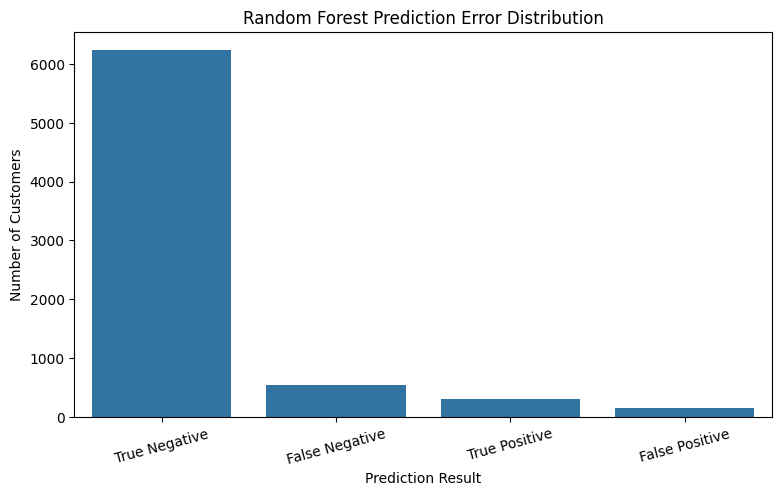

In [25]:
# Count prediction results
result_counts = error_analysis['Result'].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=result_counts.index,
    y=result_counts.values
)

plt.title("Random Forest Prediction Error Distribution")
plt.xlabel("Prediction Result")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

### Findings from Error Analysis

I identified two important patterns:

1. Call Duration:
   False Negatives had an average call duration of 481.88 seconds,
   compared with 643.73 seconds for True Positives. This suggests
   that customers with shorter calls are more likely to be missed.

2. Previous Campaign History:
   False Negatives had an average of 0.77 previous contacts,
   compared with 1.89 for True Positives. This suggests that
   customers with less previous campaign history are harder
   for the model to identify.

The pdays feature also showed a difference. Its median was -1
for False Negatives and 87 for True Positives. In this dataset,
-1 indicates that the customer was not previously contacted.

These patterns suggest that campaign history and call duration
may influence the model's predictions.

## Step 5: Improving the Model

In this step, I will try different techniques to improve
the Random Forest model's ability to identify the minority class.

I will test class weighting, different prediction thresholds
and oversampling.

I will change one thing at a time and compare precision,
recall and F1-score for the minority class.

All experiments will use training data and the validation set.
The test set will remain untouched.

In [26]:
# Random Forest with balanced class weights

balanced_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

# Train model
balanced_rf.fit(X_train_sub, y_train_sub)

# Predict validation data
balanced_pred = balanced_rf.predict(X_val)

# Evaluate
print("RANDOM FOREST WITH BALANCED CLASS WEIGHTS")

print("\nAccuracy:", accuracy_score(y_val, balanced_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    balanced_pred,
    target_names=['No', 'Yes'],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, balanced_pred))

RANDOM FOREST WITH BALANCED CLASS WEIGHTS

Accuracy: 0.901022947193807

Classification Report:
              precision    recall  f1-score   support

          No       0.91      0.98      0.95      6388
         Yes       0.68      0.29      0.41       846

    accuracy                           0.90      7234
   macro avg       0.80      0.64      0.68      7234
weighted avg       0.89      0.90      0.88      7234


Confusion Matrix:
[[6270  118]
 [ 598  248]]


In [27]:
# Get probability predictions from the original Random Forest
rf_proba = rf_model.predict_proba(X_val)[:, 1]

# Threshold values to test
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

threshold_results = []

for threshold in thresholds:

    # Convert probabilities into class predictions
    threshold_pred = (rf_proba >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(
        y_val, threshold_pred, zero_division=0
    )

    recall = recall_score(
        y_val, threshold_pred, zero_division=0
    )

    f1 = f1_score(
        y_val, threshold_pred, zero_division=0
    )

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

# Display results
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.5,0.6603,0.3676,0.4723
1,0.4,0.6194,0.5733,0.5955
2,0.3,0.5321,0.7151,0.6102
3,0.2,0.4565,0.8381,0.5911
4,0.1,0.3585,0.9374,0.5186


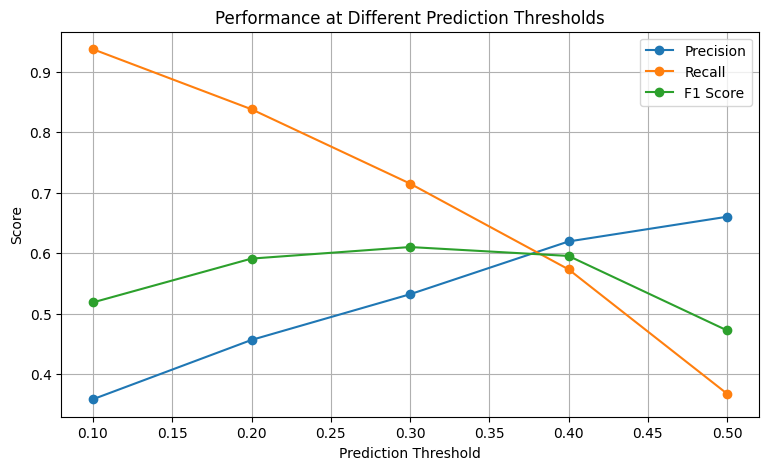

In [28]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.xlabel("Prediction Threshold")
plt.ylabel("Score")
plt.title("Performance at Different Prediction Thresholds")

plt.legend()
plt.grid(True)
plt.show()

In [29]:
# Combine training features and target
train_data = X_train_sub.copy()
train_data['target'] = y_train_sub

# Separate majority and minority classes
majority = train_data[train_data['target'] == 0]
minority = train_data[train_data['target'] == 1]

# Oversample minority class
minority_oversampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=42
)

# Combine both classes
oversampled_data = pd.concat([
    majority,
    minority_oversampled
])

# Shuffle training data
oversampled_data = oversampled_data.sample(
    frac=1,
    random_state=42
)

# Separate features and target
X_train_over = oversampled_data.drop('target', axis=1)
y_train_over = oversampled_data['target']

print("Original Training Distribution:")
print(y_train_sub.value_counts())

print("\nOversampled Training Distribution:")
print(y_train_over.value_counts())

Original Training Distribution:
y
0    25549
1     3385
Name: count, dtype: int64

Oversampled Training Distribution:
target
1    25549
0    25549
Name: count, dtype: int64


In [30]:
# Create Random Forest model
oversampled_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=42
    ))
])

# Train on oversampled training data
oversampled_rf.fit(X_train_over, y_train_over)

# Predict validation data
oversampled_pred = oversampled_rf.predict(X_val)

# Evaluate
print("OVERSAMPLED RANDOM FOREST RESULTS")

print("\nAccuracy:", accuracy_score(y_val, oversampled_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    oversampled_pred,
    target_names=['No', 'Yes'],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, oversampled_pred))

OVERSAMPLED RANDOM FOREST RESULTS

Accuracy: 0.9040641415537738

Classification Report:
              precision    recall  f1-score   support

          No       0.93      0.96      0.95      6388
         Yes       0.62      0.48      0.54       846

    accuracy                           0.90      7234
   macro avg       0.77      0.72      0.74      7234
weighted avg       0.90      0.90      0.90      7234


Confusion Matrix:
[[6138  250]
 [ 444  402]]


In [31]:
# Helper function to calculate rare-class metrics
def get_metrics(y_true, predictions):

    return {
        'Precision': precision_score(
            y_true, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_true, predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, predictions, zero_division=0
        )
    }

# Baseline model
results = []

results.append({
    'Version': 'Baseline Random Forest',
    **get_metrics(y_val, rf_pred)
})

# Balanced model
results.append({
    'Version': 'Class Weight Balanced',
    **get_metrics(y_val, balanced_pred)
})

# Threshold experiments
for threshold in thresholds:

    pred = (rf_proba >= threshold).astype(int)

    results.append({
        'Version': f'Threshold {threshold}',
        **get_metrics(y_val, pred)
    })

# Oversampling model
results.append({
    'Version': 'Oversampling',
    **get_metrics(y_val, oversampled_pred)
})

# Final comparison table
improvement_table = pd.DataFrame(results)

display(improvement_table.round(4))

,Version,Precision,Recall,F1 Score
0,Baseline Random Forest,0.6579,0.3546,0.4608
1,Class Weight Balanced,0.6776,0.2931,0.4092
2,Threshold 0.5,0.6603,0.3676,0.4723
3,Threshold 0.4,0.6194,0.5733,0.5955
4,Threshold 0.3,0.5321,0.7151,0.6102
5,Threshold 0.2,0.4565,0.8381,0.5911
6,Threshold 0.1,0.3585,0.9374,0.5186
7,Oversampling,0.6166,0.4752,0.5367


In [32]:
# Find experiment with highest recall
best_index = improvement_table['Recall'].idxmax()

print("Best Experiment Based on Recall:")
display(improvement_table.loc[[best_index]].round(4))

Best Experiment Based on Recall:


,Version,Precision,Recall,F1 Score
6,Threshold 0.1,0.3585,0.9374,0.5186


### Step 5: Results and Observations

I experimented with balanced class weights, different prediction thresholds, and oversampling to improve the model's performance on the minority class.

The balanced class weights did not improve recall. However, lowering the prediction threshold significantly improved the model's ability to identify actual subscribers.

At the threshold of 0.1, recall increased to **93.74%**, compared with approximately 35% for the baseline model. However, precision decreased to 35.85%, meaning more non-subscribers were incorrectly classified as potential subscribers.

The threshold of 0.3 achieved the highest F1-score of 0.6102, providing a better balance between precision and recall.

Overall, lowering the threshold improved minority-class detection, but it also increased false positives.

Step 6: Feature Importance

In [33]:
# Get feature names after preprocessing
feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance from Random Forest
importances = rf_model.named_steps['classifier'].feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)

# Display top 10 features
display(importance_df.head(10).round(4))

,Feature,Importance
3,num__duration,0.2645
1,num__balance,0.0999
0,num__age,0.0948
2,num__day,0.0835
46,cat__poutcome_success,0.0426
5,num__pdays,0.0401
4,num__campaign,0.0386
6,num__previous,0.0244
44,cat__poutcome_failure,0.0191
32,cat__month_apr,0.0138


Explanation of the top 3 features
1. Duration (0.2645): Call duration is the most important feature. Longer calls may be associated with a higher chance of a customer subscribing.
2. Balance (0.0999): A customer's account balance may help the model identify differences in subscription behaviour.
3. Age (0.0948): Customer age may help the model identify patterns among different age groups.

Important: Possible data leakage
The duration feature needs special attention. It represents the length of a call, which is only known after the call has ended.

If the bank wants to predict whether someone will subscribe before making the call, duration would not be available. Using it in that situation creates a feature availability problem (often called data leakage).

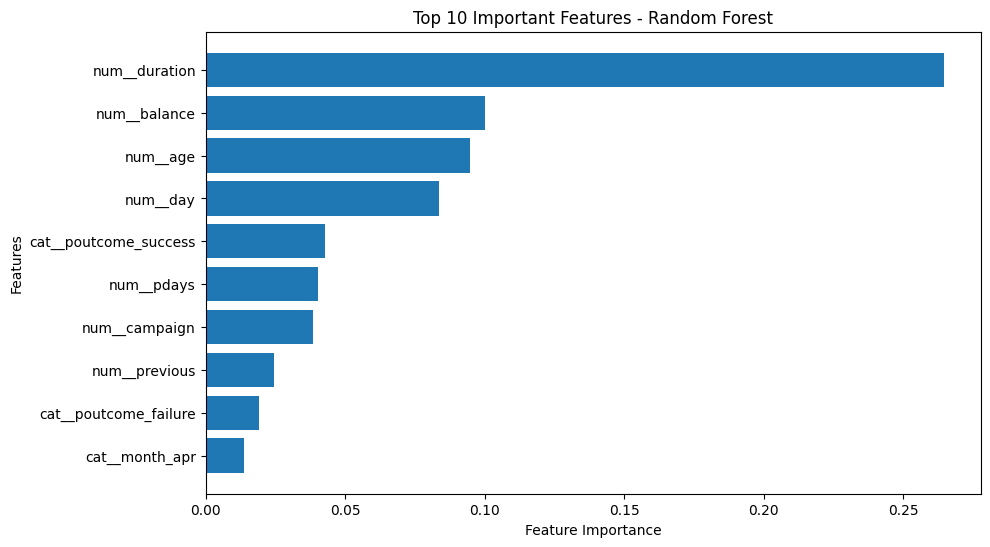

In [34]:
top_10 = importance_df.head(10).sort_values(
    by='Importance', ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(top_10['Feature'], top_10['Importance'])

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Random Forest")

plt.show()

In [35]:
# Group encoded feature importances by their original columns

grouped_importance = []

for name, transformer, columns in preprocessor.transformers_:

    if name == 'remainder':
        continue

    feature_slice = preprocessor.output_indices_[name]
    values = importances[feature_slice]

    if name == 'num':
        for col, value in zip(columns, values):
            grouped_importance.append({
                'Feature': col,
                'Importance': value
            })

    elif name == 'cat':
        encoder = next(
            step for step in transformer.named_steps.values()
            if hasattr(step, 'categories_')
        )

        position = 0

        for col, categories in zip(columns, encoder.categories_):
            count = len(categories)

            grouped_importance.append({
                'Feature': col,
                'Importance': values[position:position + count].sum()
            })

            position += count

grouped_df = pd.DataFrame(grouped_importance)
grouped_df = grouped_df.sort_values(
    by='Importance', ascending=True
)

display(grouped_df.round(4))

,Feature,Importance
10,default,0.0027
13,contact,0.0112
12,loan,0.0129
11,housing,0.0244
6,previous,0.0244
8,marital,0.0267
9,education,0.0292
4,campaign,0.0386
5,pdays,0.0401
15,poutcome,0.0678


In [36]:
# Features with the lowest importance
features_to_remove = ['default', 'contact', 'loan']

# Create reduced training and validation datasets
X_train_reduced = X_train_sub.drop(columns=features_to_remove)
X_val_reduced = X_val.drop(columns=features_to_remove)

print("Original number of features:", X_train_sub.shape[1])
print("Reduced number of features:", X_train_reduced.shape[1])

Original number of features: 16
Reduced number of features: 13


In [40]:
# Identify numerical and categorical columns
num_features_reduced = X_train_reduced.select_dtypes(
    include=np.number
).columns.tolist()

cat_features_reduced = X_train_reduced.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
num_transformer_reduced = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
cat_transformer_reduced = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor_reduced = ColumnTransformer(transformers=[
    ('num', num_transformer_reduced, num_features_reduced),
    ('cat', cat_transformer_reduced, cat_features_reduced)
])

In [41]:
reduced_rf = Pipeline(steps=[
    ('preprocessor', preprocessor_reduced),
    ('classifier', RandomForestClassifier(random_state=42))
])

reduced_rf.fit(X_train_reduced, y_train_sub)

# Predict on validation data
reduced_pred = reduced_rf.predict(X_val_reduced)

print("RANDOM FOREST AFTER FEATURE REMOVAL")

print("\nAccuracy:", accuracy_score(y_val, reduced_pred))

print("\nClassification Report:")
print(classification_report(
    y_val, reduced_pred,
    target_names=['No', 'Yes'],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, reduced_pred))

RANDOM FOREST AFTER FEATURE REMOVAL

Accuracy: 0.903511197124689

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.97      0.95      6388
         Yes       0.65      0.38      0.48       846

    accuracy                           0.90      7234
   macro avg       0.79      0.68      0.71      7234
weighted avg       0.89      0.90      0.89      7234


Confusion Matrix:
[[6214  174]
 [ 524  322]]


In [39]:
comparison = pd.DataFrame([
    {
        'Model': 'Original Random Forest',
        'Precision': precision_score(y_val, rf_pred),
        'Recall': recall_score(y_val, rf_pred),
        'F1 Score': f1_score(y_val, rf_pred)
    },
    {
        'Model': 'After Removing 3 Features',
        'Precision': precision_score(y_val, reduced_pred),
        'Recall': recall_score(y_val, reduced_pred),
        'F1 Score': f1_score(y_val, reduced_pred)
    }
])

display(comparison.round(4))

,Model,Precision,Recall,F1 Score
0,Original Random Forest,0.6579,0.3546,0.4608
1,After Removing 3 Features,0.6492,0.3806,0.4799


### Feature Importance and Feature Removal Analysis

The feature importance analysis showed that duration was the
most important feature (0.2645), followed by balance (0.0999)
and age (0.0948).

Duration may cause feature availability leakage because its
value is only known after a customer call has ended.

The three least important features were default, contact,
and loan. After removing these features, recall improved
from 0.3546 to 0.3806, and F1-score improved from 0.4608
to 0.4799.

Precision decreased slightly from 0.6579 to 0.6492.

Overall, removing the three least important features
provided a small improvement in model performance.

Step 7: Final model evaluation

In [42]:

# Final Random Forest model
final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Train using the complete training set
final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [43]:
# Use the selected threshold
final_threshold = 0.1

# Get probabilities for the positive class
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply threshold
final_test_pred = (
    test_probabilities >= final_threshold
).astype(int)

# Evaluate final model
print("FINAL MODEL TEST RESULTS")

print("\nAccuracy:",
      accuracy_score(y_test, final_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_test_pred,
    target_names=['No', 'Yes'],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_test_pred))

print("\nPrecision:",
      precision_score(y_test, final_test_pred))

print("Recall:",
      recall_score(y_test, final_test_pred))

print("F1 Score:",
      f1_score(y_test, final_test_pred))

FINAL MODEL TEST RESULTS

Accuracy: 0.8038261638836669

Classification Report:
              precision    recall  f1-score   support

          No       0.99      0.79      0.88      7985
         Yes       0.37      0.92      0.52      1058

    accuracy                           0.80      9043
   macro avg       0.68      0.85      0.70      9043
weighted avg       0.91      0.80      0.84      9043


Confusion Matrix:
[[6300 1685]
 [  89  969]]

Precision: 0.36510926902788243
Recall: 0.9158790170132325
F1 Score: 0.5220905172413793


In [44]:
final_comparison = pd.DataFrame([
    {
        'Version': 'Baseline Random Forest',
        'Accuracy': accuracy_score(y_val, rf_pred),
        'Precision': precision_score(y_val, rf_pred),
        'Recall': recall_score(y_val, rf_pred),
        'F1 Score': f1_score(y_val, rf_pred)
    },
    {
        'Version': 'Final Random Forest (Threshold 0.1)',
        'Accuracy': accuracy_score(y_test, final_test_pred),
        'Precision': precision_score(y_test, final_test_pred),
        'Recall': recall_score(y_test, final_test_pred),
        'F1 Score': f1_score(y_test, final_test_pred)
    }
])

display(final_comparison.round(4))

,Version,Accuracy,Precision,Recall,F1 Score
0,Baseline Random Forest,0.9030,0.6579,0.3546,0.4608
1,Final Random Forest (Threshold 0.1),0.8038,0.3651,0.9159,0.5221


### Step 7: Final Model Evaluation and Conclusion

The final Random Forest model was trained using the complete training dataset and evaluated on the untouched test dataset with a prediction threshold of 0.1.

The model achieved:

- Accuracy: 80.38%
- Precision: 36.51%
- Recall: 91.59%
- F1-score: 52.21%

The model correctly identified 969 out of 1,058 actual subscribers and missed only 89 subscribers.

Compared with the baseline validation results, the final model achieved substantially higher recall. However, its precision and accuracy were lower because it generated more false positives.

Since the main objective of this project is to identify as many potential subscribers as possible, I would select the final Random Forest model with a threshold of 0.1.

This model is suitable when missing potential subscribers is more costly than contacting some customers who may not subscribe. However, the bank should consider the additional marketing cost caused by false positives.

One limitation is that the model uses call duration, which is only available after a call. Therefore, its predictions may not be suitable for identifying potential subscribers before making calls.